# DPNN 벤치마크 EMS

연구 트랙 B(README 12개월 연구). 경제성 평가 파이프라인(`ess_pv_pipeline.ipynb`)과 역할이 다르다.

**벤치마크 논문**: Liu, Zhao & He (2026), *Energy Economics* 154, 109104 — Economic emission
dispatch를 **Deep Projection Neural Network**로 푼다. 동적 파라미터를 입력받아 반복 없이
최적해를 즉시 출력하는 최적화 대리모델이며, 우리는 이것을 **개발하지 않고 고정 벤치마크로 쓴다.**

**2계층 구조**

| 계층 | 하는 일 | 절 |
| --- | --- | --- |
| 완전예지 LP (연간) | 비교 상한선, 피크 목표 $\bar P_{peak}$ 산출 | 1 |
| 초단기 보정 (15분) | 실측을 받아 즉시 보정 — PNN → DPNN | 2, 3 |

설계 근거는 **`reference/dpnn_feasibility.md`**에 있고, 파라미터는
**`reference/parameters.md`**가 단일 진실 공급원이다(ESS 6,778kWh/1,355.6kW,
배출권 25,500원/tCO2). 이 노트북은 코드가 하는 일만 설명한다.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import scipy.sparse as sp
from scipy.optimize import linprog, minimize
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=4, suppress=True)
torch.set_num_threads(10)
torch.manual_seed(0)

# 설비·요금 파라미터 (reference/parameters.md)
DT_H = 0.25
# parameters.md (1)절과 동일 (캠퍼스 일평균 부하의 2.56%)
C_ESS = 6778.0                                   # kWh, 조원 경제성 모델 LP 최적값
ESS_HOURS = 5                                    # 공고 기후부 제2026-335호: ESS 5h 방전 기준
C_PCS = C_ESS / ESS_HOURS                        # kW -> 1,355.6kW
ROUND_TRIP_EFF = 0.83                            # Li-ion 왕복효율 80~86% 중간값, Elalfy 2024
ETA_CH = ETA_DIS = float(ROUND_TRIP_EFF ** 0.5)  # 충·방전에 반씩 배분
SOC_MIN, SOC_MAX, SOC_INIT = 0.20, 0.90, 0.50
C_BAT_REPLACEMENT, N_EFC = 100_000, 5000         # 원/kWh-capacity, EFC (Gasper et al. 2023)
C_DEG = C_BAT_REPLACEMENT / (2 * N_EFC)          # 10원/kWh-throughput
C_PV_FIX = 640.0                                 # kW
CONTRACT_KW, C_PEAK, PEAK_MONTHS = 30000.0, 6980.0, 12
CLIMATE_WON, FUEL_WON, TAX_F = 9.0, 5.0, 1.132   # 기후환경·연료비조정·(기금+부가세)
# 배출권 가격: 발표자료 p.30 의 2025년 SKKU 실제 매입단가 (지도교수 제시 51/76 USD는 재문의 중)
CO2_FACTOR_KR, CARBON_PRICE = 0.45941, 25_500.0
M_PEAK = C_PEAK * PEAK_MONTHS * TAX_F            # 피크 1kW의 연간 한계비용 = 94,816원


def c_grid_of(tariff):
    # 한전에서 1kW를 한 구간(15분) 사는 총비용: 청구서 전 항목 + 탄소배출권
    return DT_H * ((tariff + CLIMATE_WON + FUEL_WON) * TAX_F
                   + CO2_FACTOR_KR / 1000 * CARBON_PRICE)


print(f"피크 한계비용 {M_PEAK:,.0f}원/kW | 최대부하 구간단가 {c_grid_of(182.6):.1f}원/kW")

피크 한계비용 94,816원/kW | 최대부하 구간단가 58.6원/kW


## 1. 완전예지 LP와 MPC

`ess_pv_pipeline.ipynb` 4단계 LP는 1년(34,944구간)을 한 번에 푸는 완전예지 최적화다. 여기서는
그것을 **비교 상한선**으로 다시 풀고(목적함수를 청구서 전 항목으로 통일), 유한 호라이즌 MPC가
그 상한에 얼마나 근접하는지 본다.

- 호라이즌 48h(192구간), 24h(96구간)마다 전진하며 SOC를 이어받음
- 종단 조건 $E_H\ge E_0$ — 없으면 호라이즌 끝에서 배터리를 비운다
- 피크는 소프트: $P_{grid,t}\le\bar P_{peak}+P_{over,t}$, $P_{over}$에 `M_PEAK` 부과
- `annual_lp()`가 내놓는 최적 피크를 MPC의 목표 $\bar P_{peak}$로 쓴다

입력(부하·PV 단위발전·TOU)은 파이프라인과 동일 스펙으로 만들고 `data/bench_inputs.npz`에 캐시한다.

In [2]:
def build_inputs():
    cache = Path("data/bench_inputs.npz")
    if cache.exists():
        z = np.load(cache)
        return z["L"], z["p_unit"], z["tariff"]

    import statsmodels.formula.api as smf
    d = pd.read_csv("data/data_long.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
    d["lnusage"] = np.log(d["usage_kwh"])
    d["temp_lag1"], d["temp_lag2"] = d["temp_c"].shift(1), d["temp_c"].shift(2)
    d["year"], d["month"] = d["date"].dt.year, d["date"].dt.month
    d["humidity_bin"] = pd.qcut(d["humidity_pct"], 6, labels=False)
    est = d.dropna(subset=["lnusage", "temp_c", "temp_lag1", "temp_lag2",
                           "humidity_pct", "precip_mm"]).copy()
    formula = ("lnusage ~ cr(temp_c, df=7) + cr(temp_lag1, df=7) + cr(temp_lag2, df=7) "
               "+ C(humidity_bin) + precip_mm + holiday + vacation + exam_period "
               "+ C(day_of_week) + C(month) + C(year) + heat_wave_advisory "
               "+ heat_wave_warning + tropical_night + heavy_snow_advisory")
    res = smf.ols(formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
    smear = float(np.exp(res.resid).mean())

    d15 = pd.read_csv("data/data.csv", parse_dates=["date"])
    d15["temp_c"] = d15["temp_c"].interpolate()
    d15["slot"] = d15.groupby("date").cumcount()
    d15["shape"] = d15["usage_kwh"] / d15.groupby("date")["usage_kwh"].transform("sum")
    cal = d15[["date"]].drop_duplicates().merge(est, on="date", how="left")
    daily = pd.DataFrame({"date": cal["date"], "kwh": np.exp(res.predict(cal)) * smear})
    lm = d15[["date", "slot", "shape"]].merge(daily, on="date").sort_values(["date", "slot"])
    L = (lm["shape"] * lm["kwh"] * 4).to_numpy()                 # kWh/15min -> kW

    G = (d15["solar_rad_15min_mj_m2"] * 1e6 / 900).to_numpy()    # MJ/m2 -> W/m2
    t_cell = d15["temp_c"].to_numpy() + (45 - 20) / 800 * G      # NOCT 45C 근사
    p_unit = ((G / 1000.0) * (1 - 0.0045 * (t_cell - 25.0)) * 0.96).clip(min=0)

    RATE = {"summer": {"off": 72.0, "mid": 116.7, "peak": 182.6},
            "spring_fall": {"off": 72.0, "mid": 86.4, "peak": 106.9},
            "winter": {"off": 76.0, "mid": 115.2, "peak": 153.9}}

    def season(m):
        return "summer" if m in (6, 7, 8) else "winter" if m in (11, 12, 1, 2) else "spring_fall"

    def band(m, h, mi):
        t = h + mi / 60
        if t >= 23 or t < 9:
            return "off"
        pk = [(10, 12), (17, 20), (22, 23)] if season(m) == "winter" else [(10, 12), (13, 17)]
        return "peak" if any(a <= t < b for a, b in pk) else "mid"

    tariff = np.array([RATE[season(m)][band(m, h, i)] for m, h, i in zip(
        d15["date"].dt.month, d15["time"].str.slice(0, 2).astype(int) % 24,
        d15["time"].str.slice(3, 5).astype(int))])

    cache.parent.mkdir(exist_ok=True)
    np.savez_compressed(cache, L=L, p_unit=p_unit, tariff=tariff)
    return L, p_unit, tariff


L, P_UNIT, TARIFF = build_inputs()
print(f"T={len(L):,}구간 | 연간부하 {L.sum()*DT_H/1e3:,.0f} MWh | "
      f"PV({C_PV_FIX:.0f}kW) {(C_PV_FIX*P_UNIT).sum()*DT_H/1e3:,.0f} MWh")

T=34,944구간 | 연간부하 96,393 MWh | PV(640kW) 867 MWh


In [3]:
def annual_lp(L, p_unit, tariff, c_ess=C_ESS, c_pcs=C_PCS):
    # 1년 전체를 한 번에: 변수 P_ch, P_dis, P_grid, P_curt (각 T), E (T+1), P_peak
    T = len(L); PV = C_PV_FIX * p_unit
    ich, idis, igrid, icurt = (np.arange(k * T, (k + 1) * T) for k in range(4))
    iE, ipk = np.arange(4 * T, 5 * T + 1), 5 * T + 1
    N = 5 * T + 2
    c = np.zeros(N)
    c[igrid], c[ich], c[idis], c[ipk] = c_grid_of(tariff), DT_H * C_DEG, DT_H * C_DEG, M_PEAK
    e0 = SOC_INIT * c_ess
    bounds = ([(0, c_pcs)] * T * 2 + [(0, CONTRACT_KW)] * T + [(0, float(v)) for v in PV]
              + [(e0, e0)] + [(SOC_MIN * c_ess, SOC_MAX * c_ess)] * (T - 1) + [(e0, e0)]
              + [(0, None)])

    R, Cc, V, b = [], [], [], []
    r = 0
    for t in range(T):                                  # 전력수지
        R += [r] * 4; Cc += [igrid[t], icurt[t], idis[t], ich[t]]; V += [1.0, -1.0, 1.0, -1.0]
        b.append(L[t] - PV[t]); r += 1
    for k in range(1, T + 1):                           # SOC 동역학 (T개 구간 전부 반영)
        R += [r] * 4; Cc += [iE[k], iE[k - 1], ich[k - 1], idis[k - 1]]
        V += [1.0, -1.0, -ETA_CH * DT_H, DT_H / ETA_DIS]; b.append(0.0); r += 1
    Ru, Cu, Vu = [], [], []
    for t in range(T):                                  # P_grid <= P_peak (피크 선형화)
        Ru += [t] * 2; Cu += [igrid[t], ipk]; Vu += [1.0, -1.0]

    t0 = time.time()
    res = linprog(c, A_ub=sp.csr_matrix((Vu, (Ru, Cu)), shape=(T, N)), b_ub=np.zeros(T),
                  A_eq=sp.csr_matrix((V, (R, Cc)), shape=(r, N)), b_eq=np.array(b),
                  bounds=bounds, method="highs")
    assert res.status == 0, res.message
    x = res.x
    return dict(cost=float(res.fun), peak=float(x[ipk]), sec=time.time() - t0,
                P_ch=x[ich], P_dis=x[idis], E=x[iE])


def run_mpc(L, p_unit, tariff, pbar_peak, H=192, APPLY=96, c_ess=C_ESS, c_pcs=C_PCS):
    # 호라이즌 H를 풀고 앞 APPLY개만 적용, SOC를 이어받아 전진
    T = len(L); PV = C_PV_FIX * p_unit
    e_cur = SOC_INIT * c_ess
    ref = {k: np.zeros(T) for k in ("P_ch", "P_dis", "P_grid", "P_curt", "P_over")}
    ref["E"] = np.zeros(T + 1); ref["E"][0] = e_cur
    n_solve, t_start = 0, time.time()

    for s in range(0, T, APPLY):
        h = min(H, T - s); sl = slice(s, s + h)
        Lh, PVh, tf = L[sl], PV[sl], tariff[sl]
        ic, idc, ig, icu, io = (np.arange(k * h, (k + 1) * h) for k in range(5))
        iE = np.arange(5 * h, 6 * h + 1)
        n = 6 * h + 1
        c = np.zeros(n)
        c[ig], c[ic], c[idc], c[io] = c_grid_of(tf), DT_H * C_DEG, DT_H * C_DEG, M_PEAK
        bnds = ([(0, c_pcs)] * h * 2 + [(0, CONTRACT_KW)] * h + [(0, float(v)) for v in PVh]
                + [(0, None)] * h + [(e_cur, e_cur)] + [(SOC_MIN * c_ess, SOC_MAX * c_ess)] * h)

        R, Cc, V, b = [], [], [], []
        r = 0
        for t in range(h):
            R += [r] * 4; Cc += [ig[t], icu[t], idc[t], ic[t]]; V += [1.0, -1.0, 1.0, -1.0]
            b.append(Lh[t] - PVh[t]); r += 1
        for k in range(1, h + 1):
            R += [r] * 4; Cc += [iE[k], iE[k - 1], ic[k - 1], idc[k - 1]]
            V += [1.0, -1.0, -ETA_CH * DT_H, DT_H / ETA_DIS]; b.append(0.0); r += 1
        Ru, Cu, Vu, bu = [], [], [], []
        for t in range(h):                              # 소프트 피크
            Ru += [t] * 2; Cu += [ig[t], io[t]]; Vu += [1.0, -1.0]; bu.append(pbar_peak)
        Ru += [h]; Cu += [iE[h]]; Vu += [-1.0]; bu.append(-SOC_INIT * c_ess)   # 종단 SOC

        res = linprog(c, A_ub=sp.csr_matrix((Vu, (Ru, Cu)), shape=(h + 1, n)), b_ub=np.array(bu),
                      A_eq=sp.csr_matrix((V, (R, Cc)), shape=(r, n)), b_eq=np.array(b),
                      bounds=bnds, method="highs")
        assert res.status == 0, f"s={s}: {res.message}"
        x = res.x; n_solve += 1; na = min(APPLY, h)
        for key, idx in (("P_ch", ic), ("P_dis", idc), ("P_grid", ig),
                         ("P_curt", icu), ("P_over", io)):
            ref[key][s:s + na] = x[idx][:na]
        ref["E"][s + 1:s + na + 1] = x[iE][1:na + 1]
        e_cur = float(x[iE][na])

    pk = ref["P_grid"].max()
    cost = float((c_grid_of(tariff) * ref["P_grid"]).sum()
                 + DT_H * C_DEG * (ref["P_ch"] + ref["P_dis"]).sum() + M_PEAK * pk)
    return dict(cost=cost, peak=pk, sec=time.time() - t_start, n_solve=n_solve,
                over=ref["P_over"].max(), ref=ref)


ANN = annual_lp(L, P_UNIT, TARIFF)
MPCREF = run_mpc(L, P_UNIT, TARIFF, ANN["peak"])
print(f"[연간 LP · 완전예지] {ANN['cost']/1e8:,.3f}억원 | 피크 {ANN['peak']:,.1f}kW | {ANN['sec']:.1f}s")
print(f"[MPC 48h]            {MPCREF['cost']/1e8:,.3f}억원 "
      f"({(MPCREF['cost']/ANN['cost']-1)*100:+.6f}%) | 피크 {MPCREF['peak']:,.1f}kW | "
      f"초과 {MPCREF['over']:.1f}kW | {MPCREF['n_solve']}회 {MPCREF['sec']:.1f}s")

[연간 LP · 완전예지] 156.272억원 | 피크 19,089.6kW | 1.5s
[MPC 48h]            156.272억원 (-0.000000%) | 피크 19,089.6kW | 초과 0.0kW | 364회 2.6s


In [4]:
# 괴리가 0인 것이 구현 오류가 아님을 확인: ESS를 키우면 다일 차익거래 여지가 생겨 괴리가 나타나야 한다
rows = []
for scale in [1.0, 100.0, 1000.0]:
    ce, cp = C_ESS * scale, C_PCS * scale
    a = annual_lp(L, P_UNIT, TARIFF, ce, cp)
    g48 = run_mpc(L, P_UNIT, TARIFF, a["peak"], 192, 96, ce, cp)["cost"] / a["cost"] - 1
    g24 = run_mpc(L, P_UNIT, TARIFF, a["peak"], 96, 96, ce, cp)["cost"] / a["cost"] - 1
    rows.append({"ESS(kWh)": ce, "일평균부하 대비(%)": ce / (L.sum() * DT_H / 364) * 100,
                 "연간LP(억원)": a["cost"] / 1e8, "MPC 48h(%)": g48 * 100, "MPC 24h(%)": g24 * 100})
display(pd.DataFrame(rows).style.format({
    "ESS(kWh)": "{:,.0f}", "일평균부하 대비(%)": "{:.2f}", "연간LP(억원)": "{:,.3f}",
    "MPC 48h(%)": "{:+.4f}", "MPC 24h(%)": "{:+.4f}"}).hide(axis="index"))

ESS(kWh),일평균부하 대비(%),연간LP(억원),MPC 48h(%),MPC 24h(%)
"6,778",2.56,156.272,-0.0000,+0.0308
"677,800",255.95,147.842,+0.2191,+0.3878
"6,778,000",2559.51,145.019,+6.1298,+6.1804


### 결과

| | 비용 | 피크 |
| --- | --- | --- |
| 연간 LP (완전예지) | 156.272억원 | 19,089.6kW |
| MPC 48h | 156.272억원 (**-0.000000%**) | 동일 |

**myopia 비용이 0이다.** 반증 테스트에서 ESS를 키우면 괴리가 나타난다 — 일평균 부하의
**256%**(677,800kWh)에서 +0.219%, **2,560%**에서 +6.13%. 캠퍼스 규모(6,778kWh = 일부하의
**2.56%**)와는 두 자릿수 차이이므로 구현 오류가 아니라 **실제 성질**이다.

이유는 ESS 규모다. 하루를 넘기는 차익거래 여지가 없어 **이 문제의 유일한 전역 결합은 연간
피크**이고, 피크 목표가 주어지면 24~48시간 호라이즌이 이미 전역 최적이다. 함의 두 가지.

1. **완전예지 조건에서 계층 제어는 연간 LP와 동일하다.** 따라서 성능 열화는 **수요충격이나
   lookahead 부재에서만** 나온다(README 4.5절). Phase 4~5 없이는 보여줄 결과가 없다.
2. **DPNN의 가치를 과장하면 안 된다.** "DPNN이 더 좋은 디스패치를 한다"는 각도는 **없다**.
   가치는 (a) 파라미터 공간 스윕 가속과 (b) 고정 벤치마크 역할뿐이다.

## 2. 초단기 보정문제와 PNN

시점 $t$에서 상위 계층의 목표 $(\bar P_{ch},\bar P_{dis},\bar P_{peak})$와 실측
$(E_t,L_t,PV_t)$가 주어졌을 때 한 구간의 디스패치를 정한다. PNN은 **선형 등식 + 박스 제약**
형태만 풀 수 있으므로($g(\cdot)$가 성분별 clamp), 그 형태로 맞춘다.

$$\min_x f(x)\quad\text{s.t.}\quad \underbrace{[1,1,-1,1,-1]}_{A}x=\underbrace{L_t-PV_t}_{D},
\qquad x\in\Omega$$

$$x=[P_{base},\,P_{over},\,P_{curt},\,P_{dis},\,P_{ch}]^\top$$

- $P_{grid}$를 $P_{base}+P_{over}$로 **분할**한다 — $P_{base}\in[0,\bar P_{peak}]$,
  $P_{over}\in[0,C_{contract}-\bar P_{peak}]$. 피크 제약이 박스가 되고 항상 실행가능해진다
- **SOC 경계도 박스로 흡수**된다: 현재 $E_t$가 주어지면 한 스텝 충·방전 상한이 산술로 정해진다
- 목적함수는 **2차 추종형**. 선형이면 한 시점 안에서 차익거래 유인이 없어 해가 자명해진다

$$f(x)=\tfrac{w_E}{2}(E_{t+1}-\bar E_{t+1})^2+\tfrac{w_u}{2}\big[(P_{ch}-\bar P_{ch})^2
+(P_{dis}-\bar P_{dis})^2\big]+c_{grid}(P_{base}+P_{over})+M_{over}P_{over}+\tfrac{\epsilon}{2}\lVert x\rVert^2$$

변수 크기가 $10^4$ 대와 $10^2$ 대로 벌어져 조건수가 나쁘므로 박스 폭 $w$로 나눠 단위박스
$y\in[0,1]^5$로 보낸다. $\tilde A=A\odot w$가 rank-1이라 투영행렬이 닫힌 형태다.

$$U=\frac{\tilde A^\top\tilde A}{\lVert\tilde A\rVert^2},\qquad
q=\frac{\tilde A^\top D}{\lVert\tilde A\rVert^2},\qquad
\frac{dz}{dt}=\lambda\Big(-Ug(z)-(I-U)\big(z-g(z)+\nabla f((I-U)g(z)+q)\big)+q\Big)$$

평형에서 $Ug(z)=q$이고 양변에 $A$를 곱하면 $Ax=D$ — **등식 제약이 자동 충족**된다. 남는 조건은
$z-g(z)$가 박스의 법추 원소라는 점과 합쳐져 KKT 조건이 된다.

In [5]:
W_U, W_E, EPS_R = 1.0, 50.0, 1e-3
M_OVER = 5000.0                    # 피크 초과 패널티(최후수단이므로 충분히 크면 해가 동일)
WMIN, F_SCALE, NX = 1e-6, 1.0e5, 5  # F_SCALE 은 보고용 목적함수 단위(기울기는 obj_scale)
A_ROW = torch.tensor([1.0, 1.0, -1.0, 1.0, -1.0], dtype=torch.float64)
PHI_NAMES = ["E_t", "L_t", "PV_t", "tariff", "pbar_peak", "pbar_ch", "pbar_dis"]


def box_and_eq(phi):
    E_t, L_t, PV_t, pk = phi[:, 0], phi[:, 1], phi[:, 2], phi[:, 4]
    hi = torch.stack([
        pk,                                                                 # P_base
        torch.clamp(CONTRACT_KW - pk, min=0.0),                             # P_over
        PV_t,                                                               # P_curt
        torch.clamp((E_t - SOC_MIN * C_ESS) * ETA_DIS / DT_H, max=C_PCS),   # P_dis (SOC 하한)
        torch.clamp((SOC_MAX * C_ESS - E_t) / (ETA_CH * DT_H), max=C_PCS),  # P_ch  (SOC 상한)
    ], 1).clamp(min=0.0)
    return torch.zeros_like(hi), hi, L_t - PV_t


def norm_problem(phi):
    lo, hi, D = box_and_eq(phi)
    w = torch.clamp(hi - lo, min=WMIN)
    At = A_ROW.to(phi.dtype) * w
    nrm2 = (At * At).sum(1, keepdim=True)
    return w, At, nrm2, At * (D.unsqueeze(1) / nrm2), D


def obj_scale(phi, w, q):
    # 목적함수를 샘플별 기울기 inf-norm 으로 정규화한다. 양수배 스케일링은 KKT 해를
    # 바꾸지 않으므로(법추 승수가 같은 배로 스케일) 안전하고, 설비 규모가 바뀌어도
    # Psi = O(1) 이 유지된다. 고정 상수로 정규화하면 설비 규모가 커질 때 Psi 가 함께
    # 커져 명시적 RK4 의 안정조건(lam*h*L <~ 2.8)을 깨뜨린다.
    g0 = _grad_raw(q.clamp(0.0, 1.0), phi, w)
    return g0.abs().amax(1, keepdim=True).clamp(min=1e-12)


def f_phys(x, phi):
    c_grid = c_grid_of(phi[:, 3])
    Ebar = phi[:, 0] + ETA_CH * DT_H * phi[:, 5] - DT_H / ETA_DIS * phi[:, 6]
    En = phi[:, 0] + ETA_CH * DT_H * x[:, 4] - DT_H / ETA_DIS * x[:, 3]
    return (0.5 * W_E * (En - Ebar) ** 2
            + 0.5 * W_U * ((x[:, 4] - phi[:, 5]) ** 2 + (x[:, 3] - phi[:, 6]) ** 2)
            + c_grid * (x[:, 0] + x[:, 1]) + M_OVER * x[:, 1]
            + 0.5 * EPS_R * (x * x).sum(1)) / F_SCALE


def _grad_raw(y, phi, w):
    x = w * y
    c_grid = c_grid_of(phi[:, 3])
    Ebar = phi[:, 0] + ETA_CH * DT_H * phi[:, 5] - DT_H / ETA_DIS * phi[:, 6]
    dE = W_E * (phi[:, 0] + ETA_CH * DT_H * x[:, 4] - DT_H / ETA_DIS * x[:, 3] - Ebar)
    gx = torch.stack([
        c_grid + EPS_R * x[:, 0],
        c_grid + M_OVER + EPS_R * x[:, 1],
        EPS_R * x[:, 2],
        W_U * (x[:, 3] - phi[:, 6]) + dE * (-DT_H / ETA_DIS) + EPS_R * x[:, 3],
        W_U * (x[:, 4] - phi[:, 5]) + dE * (ETA_CH * DT_H) + EPS_R * x[:, 4],
    ], 1)
    return gx * w


def grad_fnorm(y, phi, w, q=None):
    # 목적함수를 샘플별 기울기 스케일로 정규화한 기울기
    q = norm_problem(phi)[3] if q is None else q
    return _grad_raw(y, phi, w) / obj_scale(phi, w, q)


def psi(z, phi, fs=None, cache=None):
    # 논문 식(11)의 Ψ, 단위박스 좌표에서.
    # fs(목적함수 스케일)는 phi 에만 의존하므로 호출자가 한 번 계산해 넘기면 재계산을 피한다.
    w, At, nrm2, q, _ = norm_problem(phi) if cache is None else cache
    fs = obj_scale(phi, w, q) if fs is None else fs
    gz = z.clamp(0.0, 1.0)
    U = lambda v: At * ((At * v).sum(1, keepdim=True) / nrm2)
    inner = z - gz + _grad_raw(gz - U(gz) + q, phi, w) / fs
    return -U(gz) - (inner - U(inner)) + q


# λT = 가상시간 예산, λh = 명시적 RK4 안정조건(≲2.8).
# λT 가 부족하면 일부 Φ 가 미수렴한다. 아래 스텝 수 스윕으로 24,000 을 확인했다.
LAM, T_END, N_STEPS = 1000.0, 24.0, 24000


@torch.no_grad()
def pnn_solve(PH, lam=LAM, T_end=T_END, n_steps=N_STEPS, record=False):
    # 고정스텝 RK4로 배치 적분. DPNN(단일 forward)과의 공정 비교 대조군
    cache = norm_problem(PH)
    w, q = cache[0], cache[3]
    fs = obj_scale(PH, w, q)
    z = q.clamp(0.0, 1.0).clone()
    h = T_end / n_steps
    F = lambda zz: lam * psi(zz, PH, fs, cache)
    traj = [z.clone()] if record else None
    for _ in range(n_steps):
        k1 = F(z); k2 = F(z + 0.5 * h * k1); k3 = F(z + 0.5 * h * k2); k4 = F(z + h * k3)
        z = z + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        if record:
            traj.append(z.clone())
    X = w * z.clamp(0.0, 1.0)
    return (X, torch.stack(traj), w) if record else X


def eq_residual(X, PH):
    return ((A_ROW.to(X.dtype) * X).sum(1) - (PH[:, 1] - PH[:, 2])).abs()


def qp_solve(row):
    # 대조군: 같은 문제를 범용 QP 솔버로
    phi = torch.as_tensor(row, dtype=torch.float64).reshape(1, -1)
    lo, hi, D = box_and_eq(phi)
    lo, hi, D = lo[0].numpy(), hi[0].numpy(), float(D[0])
    A = A_ROW.numpy().reshape(1, -1)
    f = lambda xn: float(f_phys(torch.as_tensor(xn, dtype=torch.float64).reshape(1, -1), phi)[0])

    def g(xn):
        xt = torch.as_tensor(xn, dtype=torch.float64).reshape(1, -1).requires_grad_(True)
        f_phys(xt, phi).sum().backward()
        return xt.grad[0].numpy()

    return minimize(f, np.clip((lo + hi) / 2, lo, hi), jac=g, method="SLSQP",
                    bounds=list(zip(lo, hi)),
                    constraints=[{"type": "eq", "fun": lambda x: A @ x - D, "jac": lambda x: A}],
                    options={"ftol": 1e-16, "maxiter": 2000}).x


print(f"보정문제 정의 완료 | 변수 {NX}개 | Φ 차원 {len(PHI_NAMES)}")

보정문제 정의 완료 | 변수 5개 | Φ 차원 7


In [6]:
# Φ: MPC 기준계획 + 예측오차성 교란 (논문의 '동적 파라미터 분포공간 O')
PK_TARGET = ANN["peak"]
REF_E, REF_ch, REF_dis = MPCREF["ref"]["E"], MPCREF["ref"]["P_ch"], MPCREF["ref"]["P_dis"]


def sample_phi(n, rng, s_load=0.05, s_pv=0.10, s_soc=0.10):
    i = rng.integers(0, len(L), n)
    return np.stack([
        np.clip(REF_E[i] * (1 + rng.normal(0, s_soc, n)), SOC_MIN * C_ESS, SOC_MAX * C_ESS),
        L[i] * (1 + rng.normal(0, s_load, n)),
        np.clip(C_PV_FIX * P_UNIT[i] * (1 + rng.normal(0, s_pv, n)), 0, None),
        TARIFF[i], np.full(n, PK_TARGET), REF_ch[i], REF_dis[i],
    ], 1)


PH_np = sample_phi(150, np.random.default_rng(7))
PH = torch.tensor(PH_np, dtype=torch.float64)
XQ = torch.tensor(np.stack([qp_solve(r) for r in PH_np]), dtype=torch.float64)
SCL = XQ.abs().amax(1).clamp(min=1.0)

rows = []
for ns in [8000, 24000, 48000]:
    t0 = time.time(); X = pnn_solve(PH, T_end=ns / LAM, n_steps=ns); el = time.time() - t0
    ok = bool(torch.isfinite(X).all())
    rows.append({"n_steps": ns, "lam*T": LAM * ns / N_STEPS * T_END, "lam*h": LAM * T_END / N_STEPS,
                 "최대 상대오차": float(((X - XQ).abs().amax(1) / SCL).max()) if ok else np.nan,
                 "등식잔차 최대(kW)": float(eq_residual(X, PH).max()) if ok else np.nan,
                 "초": el})
display(pd.DataFrame(rows).style.format({
    "n_steps": "{:,.0f}", "lam*T": "{:,.0f}", "lam*h": "{:.3f}", "최대 상대오차": "{:.2e}",
    "등식잔차 최대(kW)": "{:.2e}", "초": "{:.2f}"}).hide(axis="index"))

XP = pnn_solve(PH)
e = (XP - XQ).abs().amax(1) / SCL
print(f"[PNN vs QP] 상대오차 중앙 {e.median():.2e} 최대 {e.max():.2e} | "
      f"등식잔차 최대 {eq_residual(XP, PH).max():.2e} kW")
print(f"  박스 경계가 활성인 좌표 수(평균): "
      f"{(torch.isclose(XP, box_and_eq(PH)[0], atol=1e-6) | torch.isclose(XP, box_and_eq(PH)[1], atol=1e-6)).double().sum(1).mean():.2f} / {NX}")
print(f"  P_over>0 샘플: {(XQ[:,1]>1e-6).sum().item()}/{len(XQ)} -- 0이면 하드 피크 제약과 동일한 해")

n_steps,lam*T,lam*h,최대 상대오차,등식잔차 최대(kW),초
"8,000","8,000",1.000,5.57e-04,3.78e-05,6.57
"24,000","24,000",1.000,2.86e-04,1.47e-05,20.25
"48,000","48,000",1.000,1.05e-04,5.40e-06,35.86


[PNN vs QP] 상대오차 중앙 2.75e-14 최대 2.86e-04 | 등식잔차 최대 1.47e-05 kW
  박스 경계가 활성인 좌표 수(평균): 3.16 / 5
  P_over>0 샘플: 0/150 -- 0이면 하드 피크 제약과 동일한 해


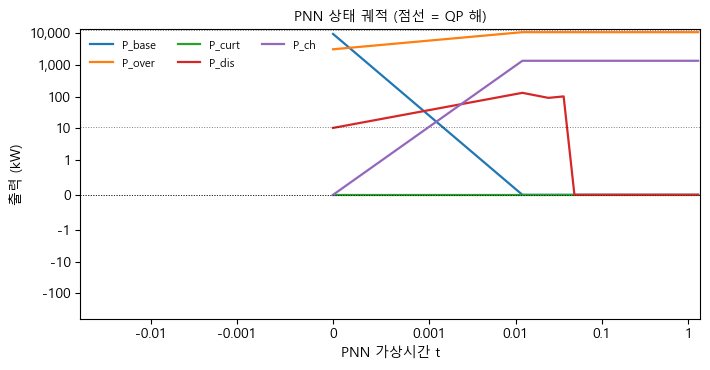

In [7]:
# 상태 궤적 (논문 Fig. 12 대응)
_, traj, w = pnn_solve(PH[:1], n_steps=2000, record=True)
tt = np.linspace(0, T_END, traj.shape[0])
xs = (traj[:, 0, :].clamp(0, 1) * w[0]).numpy()

fig, ax = plt.subplots(figsize=(7.2, 3.8))
for k, nm in enumerate(["P_base", "P_over", "P_curt", "P_dis", "P_ch"]):
    ax.plot(tt, xs[:, k], lw=1.6, label=nm)
    ax.axhline(XQ[0, k], color="k", ls=":", lw=0.7, alpha=0.5)
ax.set_xscale("symlog", linthresh=1e-3)
ax.set_yscale("symlog", linthresh=1.0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, q: f"{v:g}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, q: f"{v:,.0f}"))
ax.set_xlabel("PNN 가상시간 t"); ax.set_ylabel("출력 (kW)")
ax.set_title("PNN 상태 궤적 (점선 = QP 해)", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## 3. DPNN

$$\hat z(s,\phi;W)=z_0(\phi)+\big(1-e^{-\kappa s}\big)\mathrm{NN}(s,\phi;W),\qquad s=t/T\in[0,1]$$

지수 게이트가 초기조건 $\hat z(0,\phi)=z_0(\phi)$를 구조적으로 보장한다. 손실은 논문 식 (20)의
**ODE 잔차**이므로 지도 데이터가 필요 없다 — PNN이 교사 역할을 한다.

$$L(G;W)=\frac{1}{|G|}\sum\left(\frac{1}{\lambda T}\frac{\partial\hat z}{\partial s}
-\Psi_{\phi}(\hat z)\right)^2\Big/\,\mathrm{psc}$$

- $\partial\hat z/\partial s$는 `torch.func.jvp`로 5개 좌표를 한 번에 얻는다
- `psc` = 좌표별 $\Psi$ 스케일. $P_{over}$ 좌표가 $M_{over}$ 때문에 나머지보다 200~400배 커서
  정규화 없이는 손실이 그 좌표에 지배된다
- collocation의 절반을 $s=1$(해를 읽는 지점)에 집중시킨다

**출력에 교대투영을 적용한다.** $\lVert\tilde A\rVert\approx2.2\times10^4$ 때문에 $\Psi$ 잔차
$10^{-5}$가 등식 위반 0.22kW에 해당해, ODE 잔차 손실만으로는 등식이 느슨하게만 강제된다.
등식이 단일 선형 제약이라 초평면 투영이 닫힌 형태이므로 박스 투영과 교대 적용한다.

$$y\leftarrow y+\tilde A\frac{D-\tilde A\cdot y}{\lVert\tilde A\rVert^2},
\qquad y\leftarrow\mathrm{clip}(y,0,1)$$

In [8]:
MODEL_PATH = Path("data/dpnn_model.pt")


class DPNN(nn.Module):
    def __init__(self, n_phi=7, hidden=256, depth=4, kappa=6.0):
        super().__init__()
        layers, d = [], 1 + n_phi
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.Tanh()]; d = hidden
        self.net = nn.Sequential(*layers, nn.Linear(d, NX))
        self.kappa = kappa
        for nm in ("mu", "sd"):
            self.register_buffer(nm, torch.zeros(n_phi) if nm == "mu" else torch.ones(n_phi))
        self.register_buffer("psc", torch.ones(NX))

    def set_norm(self, PHn):
        self.mu, self.sd = PHn.mean(0), PHn.std(0).clamp(min=1e-8)
        self.psc = psi(norm_problem(PHn)[3].clamp(0, 1), PHn).pow(2).mean(0).sqrt().clamp(min=1e-6)

    def forward(self, s, phi):
        z0 = norm_problem(phi)[3].clamp(0.0, 1.0)
        return z0 + (1.0 - torch.exp(-self.kappa * s)) * self.net(
            torch.cat([s, (phi - self.mu) / self.sd], 1))


def dpnn_loss(model, PHb, p_end=0.5):
    B = PHb.shape[0]
    cache = norm_problem(PHb)
    fs = obj_scale(PHb, cache[0], cache[3])
    s = torch.rand(B, 1, dtype=PHb.dtype)
    s = torch.where(torch.rand(B, 1) < p_end, torch.ones_like(s), s)
    z, dz = torch.func.jvp(lambda ss: model(ss, PHb), (s,), (torch.ones_like(s),))
    return (((dz / (T_END * LAM) - psi(z, PHb, fs, cache)) / model.psc) ** 2).mean()


def train_dpnn(model, rng, steps=6000, batch=768, lr=3e-3, log=1500):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr * 0.01)
    hist = []
    for it in range(steps + 1):
        loss = dpnn_loss(model, torch.tensor(sample_phi(batch, rng), dtype=torch.float64))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sch.step()
        if it % log == 0:
            hist.append((it, loss.item())); print(f"  it {it:5d}  loss {loss.item():.4e}", flush=True)
    return hist


@torch.no_grad()
def project_feasible(y, PHb, iters=10):
    _, At, nrm2, _, D = norm_problem(PHb)
    for _ in range(iters):
        y = y + At * ((D.unsqueeze(1) - (At * y).sum(1, keepdim=True)) / nrm2)
        y = y.clamp(0.0, 1.0)
    return y + At * ((D.unsqueeze(1) - (At * y).sum(1, keepdim=True)) / nrm2)


@torch.no_grad()
def dpnn_predict(model, PHb, n_proj=10):
    y = model(torch.ones(PHb.shape[0], 1, dtype=PHb.dtype), PHb)
    y = y.clamp(0.0, 1.0) if n_proj == 0 else project_feasible(y, PHb, n_proj)
    return norm_problem(PHb)[0] * y


MODEL = DPNN().double()
MODEL.set_norm(torch.tensor(sample_phi(30000, np.random.default_rng(99)), dtype=torch.float64))
print(f"Ψ 좌표별 스케일 = {np.round(MODEL.psc.numpy(), 3)}")

HIST = None
if MODEL_PATH.exists():
    try:
        _ck = torch.load(MODEL_PATH, weights_only=False)
        MODEL.load_state_dict(_ck["state"]); HIST = _ck["hist"]
        print(f"캐시 로드: {MODEL_PATH} (마지막 loss {HIST[-1][1]:.4e})")
    except Exception as exc:
        print(f"캐시 불일치({type(exc).__name__}) -> 재학습")
if HIST is None:
    print("학습 시작 (CPU 10스레드에서 약 25분)")
    t0 = time.time(); HIST = train_dpnn(MODEL, np.random.default_rng(3))
    print(f"학습 {time.time()-t0:.1f}s")
    torch.save({"state": MODEL.state_dict(), "hist": HIST}, MODEL_PATH)

Ψ 좌표별 스케일 = [0.426 0.748 0.004 0.06  0.053]
캐시 로드: data\dpnn_model.pt (마지막 loss 1.4969e-03)


In [9]:
def quality(tag, X):
    e = (X - XQ).abs().amax(1) / SCL
    gap = (f_phys(X, PH) - f_phys(XQ, PH)) / f_phys(XQ, PH).abs().clamp(min=1e-12) * 100
    return {"방법": tag, "상대오차 중앙": float(e.median()), "상대오차 최대": float(e.max()),
            "목적함수 초과 중앙(%)": float(gap.median()), "목적함수 초과 최대(%)": float(gap.max()),
            "등식잔차 최대(kW)": float(eq_residual(X, PH).max())}


display(pd.DataFrame([
    quality(f"PNN (RK4 {N_STEPS:,}스텝)", XP),
    quality("DPNN 원시 (clamp만)", dpnn_predict(MODEL, PH, n_proj=0)),
    quality("DPNN + 교대투영 10회", dpnn_predict(MODEL, PH, n_proj=10)),
]).style.format({"상대오차 중앙": "{:.3e}", "상대오차 최대": "{:.3e}",
                 "목적함수 초과 중앙(%)": "{:+.4f}", "목적함수 초과 최대(%)": "{:+.4f}",
                 "등식잔차 최대(kW)": "{:.3e}"}).hide(axis="index"))

# 파라미터 공간 스윕 속도 — PNN은 반복 적분, DPNN은 1회 forward
sweep = []
for n in [1000, 5000, 20000]:
    P = torch.tensor(sample_phi(n, np.random.default_rng(5)), dtype=torch.float64)
    t0 = time.time(); pnn_solve(P); tp = time.time() - t0   # 반복 적분
    t0 = time.time(); dpnn_predict(MODEL, P); td = time.time() - t0
    sweep.append({"Φ 샘플 수": n, "PNN(초)": tp, "DPNN(초)": td, "가속": tp / max(td, 1e-9)})
display(pd.DataFrame(sweep).style.format({
    "Φ 샘플 수": "{:,.0f}", "PNN(초)": "{:,.2f}", "DPNN(초)": "{:.3f}",
    "가속": "{:,.0f}x"}).hide(axis="index"))
print(f"스트레스 테스트 1개 조합 = {len(L):,}구간 -> 조합 100개면 {len(L)*100/1e6:.1f}백만 회 해")

방법,상대오차 중앙,상대오차 최대,목적함수 초과 중앙(%),목적함수 초과 최대(%),등식잔차 최대(kW)
"PNN (RK4 24,000스텝)",2.753e-14,2.857e-04,+0.0000,+0.0061,1.470e-05
DPNN 원시 (clamp만),3.669e-03,7.595e-02,+0.3667,+4.5546,6.546e+02
DPNN + 교대투영 10회,4.189e-03,1.236e-02,+0.9615,+3.8741,3.638e-12


Φ 샘플 수,PNN(초),DPNN(초),가속
"1,000",32.78,0.010,"3,445x"
"5,000",95.81,0.031,"3,070x"
"20,000",426.66,0.120,"3,542x"


스트레스 테스트 1개 조합 = 34,944구간 -> 조합 100개면 3.5백만 회 해


## 정리

| | 상태 |
| --- | --- |
| 완전예지 LP · MPC | **완료** — myopia **-0.000000%**, 반증 테스트 통과(임계 일부하의 256%) |
| PNN | **완료** — QP와 중앙 2.8e-14 / 최대 2.9e-04, 목적함수 초과 **+0.0000%** |
| DPNN | **완료** — 교대투영 후 목적함수 초과 중앙 **+0.96%** / 최대 +3.87%, 등식 기계정밀도 |
| 스윕 가속 | **완료** — Φ 1천~2만개에서 **약 3,000~3,500배** |

**해 품질 (n=150, present 기준 Φ)**

| 방법 | 상대오차 중앙 | 최대 | 목적함수 초과 중앙 | 최대 | 등식잔차 최대 |
| --- | --- | --- | --- | --- | --- |
| PNN (RK4) | 2.75e-14 | 2.86e-04 | +0.0000% | +0.0061% | 1.5e-05 kW |
| DPNN 원시(clamp만) | 3.67e-03 | 7.60e-02 | +0.367% | +4.55% | 654.6 kW |
| **DPNN + 교대투영 10회** | 4.19e-03 | 1.24e-02 | **+0.962%** | +3.87% | **3.6e-12 kW** |

투영은 목적함수를 약간 희생하고(+0.37% → +0.96%) **등식을 기계정밀도로 복원**한다. 실행가능성이
중요하므로 투영을 채택한다.

### 이 단계에서 얻은 교훈 — 고정 스케일 상수는 설비 규모와 함께 깨진다

ESS 규모를 15.8배로 키우면 고정 상수 정규화($F_{scale}=10^5$) 아래에서 $\Psi$가 $O(30)$이 되어
명시적 RK4의 안정조건($\lambda h L\lesssim2.8$)을 깨뜨리고, PNN 상대오차가 2.8e-14에서 **0.31**로
무너진다. 스텝 수를 2배로 올려도 고쳐지지 않으므로 안정성이 아닌 **스케일 문제**다.
→ 목적함수를 **샘플별 기울기 inf-norm**으로 정규화해 해결한다(양수배 스케일링은 KKT 해를 바꾸지
않는다). **파라미터를 바꿀 때 수치 설정도 함께 검증해야 한다**는 사례다.

### 확정된 연구 서술

1. 완전예지에서 계층 제어 = 연간 LP이므로 **수요충격이나 lookahead 부재 없이는 열화가 없다.**
   README 4.5절의 분해(완전예지 vs 반응형)가 결과의 전부다.
2. DPNN의 가치는 **스윕 가속 + 고정 벤치마크** 두 가지뿐이다.
3. 논문의 비지도 ODE-잔차 손실은 그 자체로는 해 정확도의 느슨한 대리지표다
   ($\lVert\tilde A\rVert\approx2.2\times10^4$ 때문에 $\Psi$ 잔차 $10^{-5}$ = 등식 위반 0.22kW).
   **등식을 구조로 강제(교대투영)**해야 쓸 수 있다 — 합성 테스트케이스에서는 드러나지 않는
   제약이며 "왜 실제 사례를 봐야 하는가"에 들어가는 재료다.

### 다음 단계 (Phase 4)

1. **AI workload 트레이스 확보** (Alibaba PAI / MIT Supercloud / PM100) — 유일한 미확보 데이터
2. **반응형 팔 구현** — 시간대 기반 SOC 목표 규칙(현재 Φ는 MPC 기준계획을 쓰므로 lookahead가 들어 있다)
3. Stress test → failure boundary, 완전예지 vs 반응형 분해

상세: `reference/dpnn_feasibility.md`, `reference/team_review_and_plan.md`